# Model review (L1) — what each model learned, how good it is, and whether it makes physical sense

Reviews the models trained by `flame/train.py` (stored in `models/*.json`) with the same cycle as the EDA: analysis → conclusions → LC decides.
For each model: (1) which versions were compared and why one won; (2) what it learned, in readable units; (3) curves: how the answer changes with each condition; (4) calibration: when it says 80 %, does it happen ~80 % of the time? (out-of-sample, grouped CV); (5) physical sanity checks.

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from flame import train as T
from flame.models import model, predict
from flame.contracts import Conditions as C
pd.set_option('display.width', 200)
M = {n: model(n) for n in ['flex_main', 'flex_breakup', 'cfig_selfext_normal', 'cfig_selfext_inverse', 'cfig_ignition']}
for n, m in M.items():
    print(f"{n:22s} n={m['n']:4d} groups={m['n_groups']:3d}  cv={m['cv']}")

flex_main              n= 200 groups= 97  cv={'log_loss': 0.2276, 'brier': 0.0685, 'auc': 0.9149, 'auc_sd': 0.0054, 'base_rate_log_loss': 0.405}
flex_breakup           n= 254 groups=114  cv={'log_loss': 0.3473, 'brier': 0.1115, 'auc': 0.8813, 'auc_sd': 0.0085, 'base_rate_log_loss': 0.5174}
cfig_selfext_normal    n= 133 groups= 22  cv={'c_index': 0.8207, 'c_index_sd': 0.006}
cfig_selfext_inverse   n= 138 groups= 68  cv={'c_index': 0.7132, 'c_index_sd': 0.011}
cfig_ignition          n= 170 groups= 22  cv={'log_loss': 0.4597, 'brier': 0.1342, 'auc': 0.7182, 'auc_sd': 0.0067, 'base_rate_log_loss': 0.5239}


## 1. FLEX main model — "if the droplet does not break up, does the flame go out before the droplet burns completely?"
### 1.1 Versions compared (grouped CV by condition combination, 5 folds × 5 repetitions)

In [2]:
sel = pd.DataFrame(M['flex_main']['selection'])
print(sel.to_string(index=False))

              features   C  log_loss  brier    auc  auc_sd  base_rate_log_loss
+ fuel x (O2, CO2, He) 1.0    0.2276 0.0685 0.9149  0.0054               0.405
+ fuel x (O2, CO2, He) 3.0    0.2309 0.0697 0.9144  0.0046               0.405
+ fuel x (O2, CO2, He) 0.3    0.2382 0.0704 0.9096  0.0066               0.405
           + fuel x O2 1.0    0.2454 0.0720 0.8949  0.0093               0.405
           + fuel x O2 3.0    0.2476 0.0730 0.8971  0.0071               0.405
    base + fuel x size 1.0    0.2515 0.0752 0.8960  0.0110               0.405
    base + fuel x size 3.0    0.2541 0.0770 0.8998  0.0091               0.405
           + fuel x O2 0.3    0.2557 0.0742 0.8835  0.0089               0.405
    base + fuel x size 0.3    0.2591 0.0761 0.8857  0.0090               0.405
+ fuel x (O2, CO2, He) 0.1    0.2627 0.0767 0.8939  0.0064               0.405
           + fuel x O2 0.1    0.2769 0.0805 0.8714  0.0066               0.405
    base + fuel x size 0.1    0.2783 0.0814 0.8728  

### 1.2 What it learned, in readable units
Coefficients are stored per 1 standard deviation of each input. Below they are converted to **odds ratios per a readable step** (e.g. per +1 point of O₂): > 1 = more likely to go out, < 1 = less likely. Interactions are shown as the effect **for heptane vs methanol**. The bootstrap interval (resampling whole condition groups) shows how sure we are.

In [3]:
def readable(m, steps):
    sd = dict(zip(m['features'], m['sd'])); coef = dict(zip(m['features'], m['coef']))
    boot = np.array(m['boot'])[:, 1:]; idx = {f: k for k, f in enumerate(m['features'])}
    rows = []
    for f, (step, label) in steps.items():
        if f not in coef: continue
        b = coef[f] / sd[f] * step; bb = boot[:, idx[f]] / sd[f] * step
        rows.append({'input': label, 'odds ratio': round(np.exp(b), 2), 'low 95%': round(np.exp(np.percentile(bb, 2.5)), 2),
                     'high 95%': round(np.exp(np.percentile(bb, 97.5)), 2)})
    return pd.DataFrame(rows)
steps = {'o2_frac': (0.01, '+1 point of O2 (methanol)'), 'co2_frac': (0.05, '+5 points of CO2 (methanol)'), 'he_frac': (0.05, '+5 points of He (methanol)'),
         'd0_mm': (1.0, '+1 mm droplet (methanol)'), 'fiber': (1.0, 'on a fiber vs free'), 'p_0p7atm': (1.0, '0.7 atm vs 1 atm'),
         'heptane_x_d0_mm': (1.0, 'extra per +1 mm if heptane'), 'heptane_x_o2_frac': (0.01, 'extra per +1 point O2 if heptane'),
         'heptane_x_co2_frac': (0.05, 'extra per +5 points CO2 if heptane'), 'heptane_x_he_frac': (0.05, 'extra per +5 points He if heptane')}
print(readable(M['flex_main'], steps).to_string(index=False))

                             input  odds ratio  low 95%  high 95%
         +1 point of O2 (methanol)        0.73     0.62      0.82
       +5 points of CO2 (methanol)        1.00     0.81      1.31
        +5 points of He (methanol)        1.30     1.16      1.51
          +1 mm droplet (methanol)        0.59     0.28      2.02
                on a fiber vs free        0.42     0.08      1.94
                  0.7 atm vs 1 atm        0.54     0.10      2.34
        extra per +1 mm if heptane       77.11    22.63    251.16
  extra per +1 point O2 if heptane        0.64     0.49      0.92
extra per +5 points CO2 if heptane        1.97     1.34      2.78
 extra per +5 points He if heptane        1.17     0.93      1.68


### 1.3 Curves: how the probability changes (other inputs at typical values; only inside tested combinations — gaps = "we don't know")

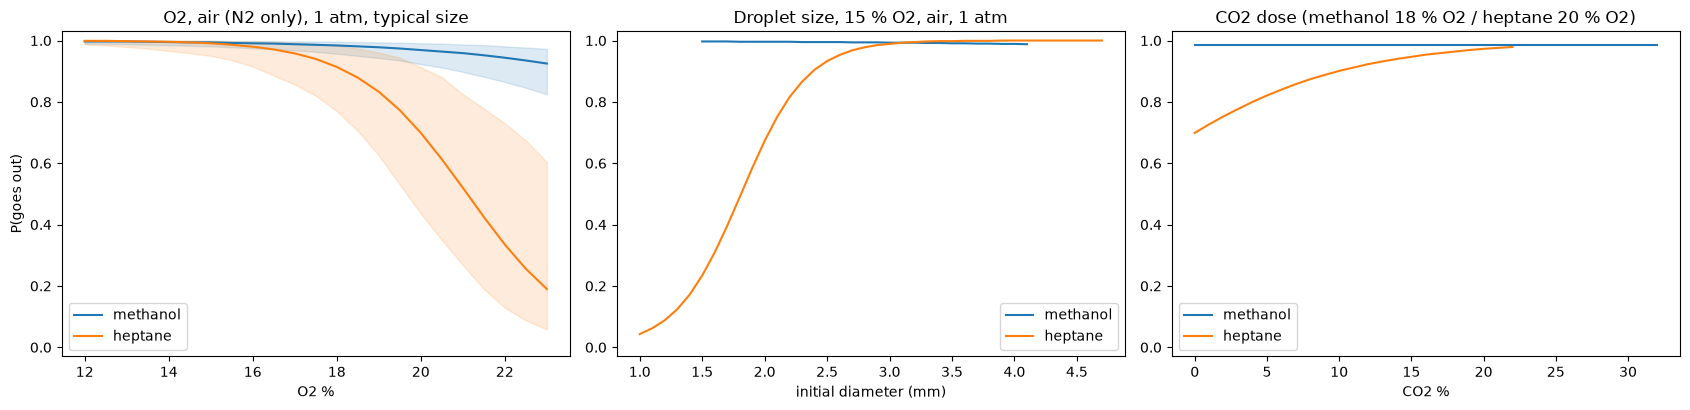

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for fuel, col in [('methanol', 'tab:blue'), ('heptane', 'tab:orange')]:
    xs = np.arange(0.12, 0.26, 0.005); ps = [predict(C(fuel=fuel, o2_frac=x))[0].probability for x in xs]
    lo = [predict(C(fuel=fuel, o2_frac=x))[0].ci_low for x in xs]; hi = [predict(C(fuel=fuel, o2_frac=x))[0].ci_high for x in xs]
    ax[0].plot(xs * 100, [p if p is not None else np.nan for p in ps], color=col, label=fuel)
    ax[0].fill_between(xs * 100, [l if l is not None else np.nan for l in lo], [h if h is not None else np.nan for h in hi], color=col, alpha=.15)
    ds = np.arange(1.0, 4.8, 0.1); ps = [predict(C(fuel=fuel, o2_frac=0.15, droplet_d0_mm=d))[0].probability for d in ds]
    ax[1].plot(ds, [p if p is not None else np.nan for p in ps], color=col, label=fuel)
    cs = np.arange(0.0, 0.40, 0.01); ps = [predict(C(fuel=fuel, o2_frac=0.18 if fuel == 'methanol' else 0.20, co2_frac=c))[0].probability for c in cs]
    ax[2].plot(cs * 100, [p if p is not None else np.nan for p in ps], color=col, label=fuel)
ax[0].set(title='O2, air (N2 only), 1 atm, typical size', xlabel='O2 %', ylabel='P(goes out)')
ax[1].set(title='Droplet size, 15 % O2, air, 1 atm', xlabel='initial diameter (mm)')
ax[2].set(title='CO2 dose (methanol 18 % O2 / heptane 20 % O2)', xlabel='CO2 %')
for a in ax: a.set_ylim(-0.03, 1.03); a.legend()
fig.tight_layout(); fig.savefig('figures/model_flex_curves.png', dpi=110); plt.show()

### 1.4 Calibration, out of sample (grouped CV with the chosen version)

In [5]:
f = pd.read_parquet('../data/processed/flex_tests.parquet')
f = f[(f['p_level'] != '2-3 atm') & f['d0_mm'].notna() & f['clean']].copy()
X, _ = T.flex_frame(f, M['flex_main']['interaction_centers']); X = X[M['flex_main']['features']]
y = f['extinct'].astype(int).values; g = f['group_id'].values
oof = np.zeros(len(y))
for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X, y, g):
    Z, mu, sd = T.standardize(X.iloc[tr]); b0, b = T.fit_logit(Z.values, y[tr], M['flex_main']['C'])
    oof[te] = 1 / (1 + np.exp(-(b0 + ((X.iloc[te] - mu) / sd).values @ b)))
cal = pd.DataFrame({'p': oof, 'y': y}).assign(bin=lambda d: pd.cut(d.p, [0, .5, .8, .9, .95, 1.0]))
print(cal.groupby('bin', observed=True).agg(n=('y', 'size'), predicted=('p', 'mean'), observed=('y', 'mean')).round(2))
print('\nwhere does it miss most? (largest out-of-sample errors)')
f['oof'] = oof
print(f.assign(err=(f['oof'] - f['extinct'].astype(int)).abs()).sort_values('err', ascending=False)
      [['flex_id', 'fuel', 'o2_frac', 'co2_frac', 'he_frac', 'd0_mm', 'support', 'test_end', 'oof']].head(8).round(2).to_string(index=False))

               n  predicted  observed
bin                                  
(0.0, 0.5]    19       0.21      0.26
(0.5, 0.8]    26       0.66      0.69
(0.8, 0.9]    17       0.85      0.82
(0.9, 0.95]   22       0.93      0.91
(0.95, 1.0]  116       0.99      0.99

where does it miss most? (largest out-of-sample errors)
flex_id     fuel  o2_frac  co2_frac  he_frac  d0_mm support   test_end  oof
C03M101 Methanol     0.18      0.15      0.0   3.86    free Completion 0.99
206R001 Methanol     0.30      0.00      0.0   2.42   fiber Extinction 0.08
194F001  Heptane     0.20      0.00      0.0   3.56    free Completion 0.91
C10M303 Methanol     0.21      0.30      0.0   3.37   fiber Completion 0.91
C10M401 Methanol     0.21      0.30      0.0   3.99   fiber Completion 0.89
C21H302  Heptane     0.24      0.20      0.0   3.08    free Completion 0.81
209F001  Heptane     0.21      0.00      0.0   3.36    free Completion 0.81
303F001  Heptane     0.20      0.00      0.0   3.10   fiber Extinctio

### 1.5 Disruption sensitivity and break-up model

In [6]:
print('break-up model — odds ratios:'); print(readable(M['flex_breakup'], steps).to_string(index=False))
for q in [C(fuel='heptane', o2_frac=0.21), C(fuel='methanol', o2_frac=0.21), C(fuel='methanol', o2_frac=0.15, he_frac=0.3)]:
    p = predict(q)
    print(f"{q.fuel:8s} O2={q.o2_frac} He={q.he_frac}: P(out)={p[0].probability} CI=[{p[0].ci_low},{p[0].ci_high}] "
          f"sensitivity={p[0].range_sensitivity} | P(break-up)={p[1].probability}")

break-up model — odds ratios:
                      input  odds ratio  low 95%  high 95%
  +1 point of O2 (methanol)        1.33     1.22      1.49
+5 points of CO2 (methanol)        0.88     0.74      1.02
 +5 points of He (methanol)        0.77     0.65      0.89
   +1 mm droplet (methanol)        0.94     0.56      1.60
         on a fiber vs free        1.78     0.61      4.42
           0.7 atm vs 1 atm        1.56     0.64      4.81
 extra per +1 mm if heptane        0.34     0.18      0.59
heptane  O2=0.21 He=None: P(out)=0.52 CI=[0.268,0.825] sensitivity=[0.313, 0.832] | P(break-up)=0.251
methanol O2=0.21 He=None: P(out)=0.959 CI=[0.898,0.987] sensitivity=[0.852, 0.966] | P(break-up)=0.134
methanol O2=0.15 He=0.3: P(out)=0.999 CI=[0.996,1.0] sensitivity=[0.995, 0.996] | P(break-up)=0.006


## 2. CFI-G self-extinction — "does a lit gas flame go out by itself within T seconds?"
### 2.1 What it learned: hazard ratios per readable step (> 1 = goes out sooner), with bootstrap interval

In [7]:
def hr_table(m, steps):
    sd = dict(zip(m['features'], m['sd'])); coef = dict(zip(m['features'], m['coef']))
    boot = np.array(m['boot_coef']); idx = {f: k for k, f in enumerate(m['features'])}
    rows = []
    for f, (step, label) in steps.items():
        if f not in coef: continue
        b = coef[f] / sd[f] * step; bb = boot[:, idx[f]] / sd[f] * step
        rows.append({'input': label, 'hazard ratio': round(np.exp(b), 2), 'low 95%': round(np.exp(np.percentile(bb, 2.5)), 2), 'high 95%': round(np.exp(np.percentile(bb, 97.5)), 2)})
    return pd.DataFrame(rows)
hs = {'o2_pct': (1, '+1 point of O2'), 'pressure_bar': (1, '+1 bar'), 'jet_fuel_frac': (0.1, '+10 points fuel in jet'), 'atm_fuel_pct': (1, '+1 point fuel in chamber'),
      'fuel_flow_mg_s': (0.5, '+0.5 mg/s fuel flow (bigger flame)'), 'ethane': (1, 'ethane vs butane'), 'propane': (1, 'propane vs butane')}
for n in ['cfig_selfext_normal', 'cfig_selfext_inverse']:
    print(f'--- {n}  (C-index {M[n]["cv"]["c_index"]})'); print(hr_table(M[n], hs).to_string(index=False)); print(pd.DataFrame(M[n]['selection']).to_string(index=False))

--- cfig_selfext_normal  (C-index 0.8207)
                             input  hazard ratio  low 95%  high 95%
                    +1 point of O2          0.77     0.73      0.81
                            +1 bar          2.28     1.21      4.49
            +10 points fuel in jet          0.96     0.77      1.11
+0.5 mg/s fuel flow (bigger flame)          1.50     1.17      2.24
                  ethane vs butane          0.54     0.28      1.05
                 propane vs butane          1.22     0.43      6.49
 alpha  c_index  c_index_sd
   3.0   0.8207      0.0060
   1.0   0.8201      0.0066
   0.3   0.8199      0.0066
  10.0   0.8173      0.0052
--- cfig_selfext_inverse  (C-index 0.7132)
                             input  hazard ratio  low 95%  high 95%
                    +1 point of O2          1.00     0.99      1.02
                            +1 bar          1.32     0.96      2.37
          +1 point fuel in chamber          0.89     0.74      0.98
+0.5 mg/s fuel flow (bigger

### 2.2 Curves: share of flames still burning over time (model) vs what NASA saw (Kaplan–Meier)

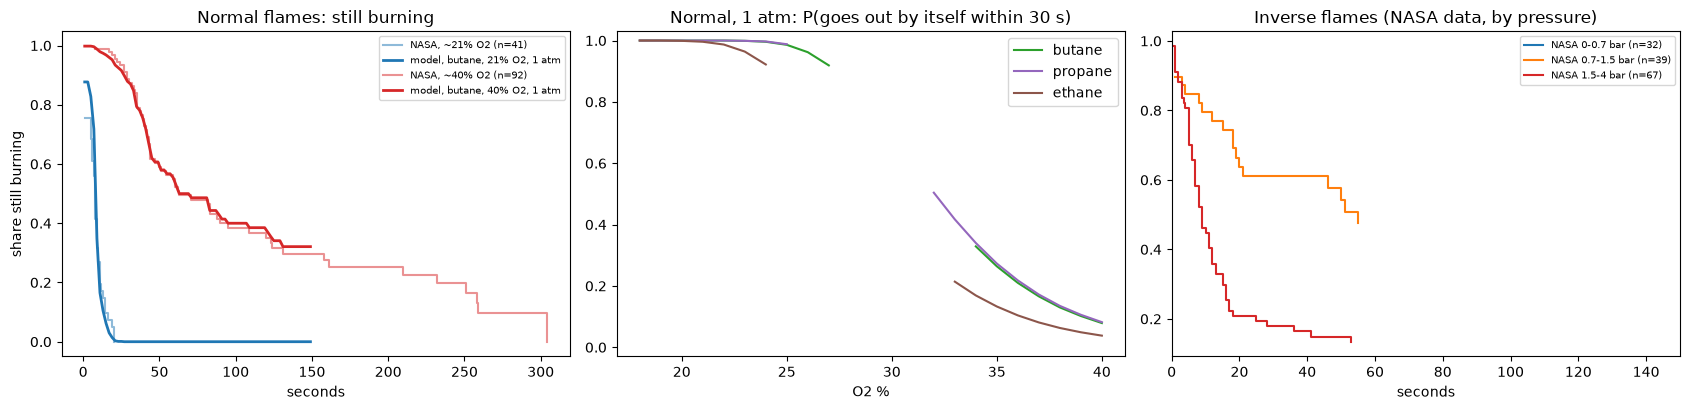

In [8]:
from statsmodels.duration.survfunc import SurvfuncRight
cf = pd.read_parquet('../data/processed/cfig_tests.parquet')
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
nE = cf[(cf.flame_type == 'normal') & cf.ext_model].dropna(subset=['burn_time_s'])
for o2, col in [(0.21, 'tab:blue'), (0.40, 'tab:red')]:
    g = nE[nE['o2_nominal'] == o2]
    sf = SurvfuncRight(g['burn_time_s'].clip(lower=.5).values, g['self_ext'].astype(int).values)
    ax[0].step(sf.surv_times, sf.surv_prob, where='post', color=col, alpha=.5, label=f'NASA, ~{o2:.0%} O2 (n={len(g)})')
    ts = np.arange(1, 150, 2)
    ps = [predict(C(fuel='butane', o2_frac=o2 if o2 < .3 else 0.38, pressure_kpa=101.3, horizon_s=t))[0].probability for t in ts]
    ax[0].plot(ts, [1 - p if p is not None else np.nan for p in ps], color=col, lw=2, label=f'model, butane, {o2:.0%} O2, 1 atm')
ax[0].set(title='Normal flames: still burning', xlabel='seconds', ylabel='share still burning'); ax[0].legend(fontsize=7)
for fuel, col in [('butane', 'tab:green'), ('propane', 'tab:purple'), ('ethane', 'tab:brown')]:
    os_ = np.arange(0.18, 0.41, 0.01)
    ps = [predict(C(fuel=fuel, o2_frac=o, pressure_kpa=101.3, horizon_s=30))[0].probability for o in os_]
    ax[1].plot(os_ * 100, [p if p is not None else np.nan for p in ps], color=col, label=fuel)
ax[1].set(title='Normal, 1 atm: P(goes out by itself within 30 s)', xlabel='O2 %', ylim=(-.03, 1.03)); ax[1].legend()
iE = cf[(cf.flame_type == 'inverse') & cf.ext_model].dropna(subset=['burn_time_s'])
for lvl, col in [((0, .7), 'tab:blue'), ((.7, 1.5), 'tab:orange'), ((1.5, 4), 'tab:red')]:
    g = iE[(iE.pressure_bar > lvl[0]) & (iE.pressure_bar <= lvl[1])]
    sf = SurvfuncRight(g['burn_time_s'].clip(lower=.5).values, g['self_ext'].astype(int).values)
    ax[2].step(sf.surv_times, sf.surv_prob, where='post', color=col, label=f'NASA {lvl[0]}-{lvl[1]} bar (n={len(g)})')
ax[2].set(title='Inverse flames (NASA data, by pressure)', xlabel='seconds', xlim=(0, 150)); ax[2].legend(fontsize=7)
fig.tight_layout(); fig.savefig('figures/model_cfig_curves.png', dpi=110); plt.show()

### 2.3 Calibration at 30 s (grouped CV by chamber atmosphere): predicted vs observed share gone out by 30 s
Flames cut by the operator before 30 s are left out of this check (their 30-s outcome is unknown).

In [9]:
for ft in ['normal', 'inverse']:
    d = cf[(cf.flame_type == ft) & cf.ext_model].dropna(subset=['burn_time_s']).copy(); d['burn_time_s'] = d['burn_time_s'].clip(lower=.5)
    X = T.cfig_frame(d, ft)[M[f'cfig_selfext_{ft}']['features']]; t_, e_ = d['burn_time_s'].values, d['self_ext'].astype(int).values
    ug = d['fill_key'].unique(); rng = np.random.RandomState(0); rng.shuffle(ug)
    fold = d['fill_key'].map({u: k % 5 for k, u in enumerate(ug)}).values; p30 = np.zeros(len(d))
    for k in range(5):
        tr, te = fold != k, fold == k
        Z, mu, sd = T.standardize(X[tr]); b = T.ridge_cox(Z.values, t_[tr], e_[tr], M[f'cfig_selfext_{ft}']['alpha'])
        H0 = T.breslow(Z.values, t_[tr], e_[tr], b, np.array([30.0]))[0]
        p30[te] = 1 - np.exp(-H0 * np.exp(((X[te] - mu) / sd).values @ b))
    known = (e_ == 1) | (t_ >= 30); obs = ((e_ == 1) & (t_ <= 30)).astype(int)
    cal = pd.DataFrame({'p': p30[known], 'y': obs[known]}).assign(bin=lambda x: pd.cut(x.p, [0, .25, .5, .75, .9, 1.0]))
    print(f'--- {ft} (n with known 30-s outcome = {known.sum()})')
    print(cal.groupby('bin', observed=True).agg(n=('y', 'size'), predicted=('p', 'mean'), observed=('y', 'mean')).round(2))

--- normal (n with known 30-s outcome = 125)
              n  predicted  observed
bin                                 
(0.0, 0.25]  67       0.13      0.07
(0.25, 0.5]  15       0.34      0.33
(0.5, 0.75]   1       0.64      1.00
(0.75, 0.9]   2       0.83      0.50
(0.9, 1.0]   40       0.99      1.00
--- inverse (n with known 30-s outcome = 129)
              n  predicted  observed
bin                                 
(0.0, 0.25]  31       0.13      0.23
(0.25, 0.5]  22       0.37      0.23
(0.5, 0.75]  32       0.64      0.72
(0.75, 0.9]  31       0.83      0.97
(0.9, 1.0]   13       0.96      0.62


## 3. CFI-G ignition — "does a normal gas flame light, given how diluted the fuel jet is?"

In [10]:
mi = M['cfig_ignition']
print('odds ratio per x2 more fuel in the jet:', round(float(np.exp(mi['coef'][0] / mi['sd'][0] * np.log10(2))), 2))
for xf in [0.02, 0.03, 0.05, 0.1, 0.3, 1.0]:
    p = predict(C(fuel='propane', o2_frac=0.21, jet_fuel_frac=xf))
    ig = [q for q in p if q.target == 'ignition']
    print(f'jet fuel {xf:>5}: P(lights) = {ig[0].probability} [{ig[0].ci_low}, {ig[0].ci_high}]' if ig else xf)
g = cf[cf.ign_model]
print('\nNASA, share lit by jet fuel band:'); print(g.groupby(pd.cut(g.jet_fuel_frac, [-.01, .03, .06, .2, 1]), observed=True)['ignited'].agg(['size', 'mean']).round(2))

odds ratio per x2 more fuel in the jet: 1.81
jet fuel  0.02: P(lights) = 0.37 [0.229, 0.853]
jet fuel  0.03: P(lights) = 0.454 [0.337, 0.862]
jet fuel  0.05: P(lights) = 0.564 [0.48, 0.873]
jet fuel   0.1: P(lights) = 0.701 [0.611, 0.873]
jet fuel   0.3: P(lights) = 0.857 [0.758, 0.951]
jet fuel   1.0: P(lights) = 0.944 [0.84, 0.99]

NASA, share lit by jet fuel band:
               size  mean
jet_fuel_frac            
(-0.01, 0.03]    14  0.00
(0.03, 0.06]     26  0.54
(0.06, 0.2]      10  1.00
(0.2, 1.0]      120  0.91


## 4. Conclusions (for LC's decision)

**FLEX main — good.** Out of sample AUC 0.91 and well calibrated (when it says ~66 % it happens 69 %; when it says ~93 %, 91 %). The chosen version (all four fuel interactions) beats the simpler ones clearly (log loss 0.228 vs 0.245–0.252).
- Physics checks pass: more O₂ → less likely to go out (×0.73 per point for methanol, stronger for heptane); helium suppresses; for heptane, CO₂ suppresses (×2 per 5 points) and size is decisive (small droplets burn out, big ones go out).
- **Caveat to state in answers:** for **methanol the model cannot separate CO₂ from O₂** (NASA lowered O₂ while raising CO₂ in the same tests, and methanol went out almost always anyway): the CO₂ effect for methanol comes out as zero. Not wrong, just not identifiable with these data.
- Biggest misses are tests that contradict their neighbours (e.g. C03M101: methanol that burned completely where almost every similar test went out). Expected noise.

**FLEX break-up — reasonable** (AUC 0.88): more O₂ → more break-ups (×1.33 per point); helium and CO₂ reduce it. Consistent with NASA's contaminated-needle explanation plus hotter flames.

**CFI-G normal flames — good.** C-index 0.82; the curve of "flames still burning" matches NASA's data almost exactly at both 21 % and 40 % O₂; calibration at 30 s is good. Each point of O₂ makes self-extinction 23 % less likely per second; +1 bar ×2.3; bigger flame ×1.5 per 0.5 mg/s.

**CFI-G inverse flames — moderate.** C-index 0.71 and rough calibration at the top (says ~96 %, happened 62 %, few flames). Physically sensible (more fuel around and bigger flames burn longer). Keep it, but answers must say "moderate confidence".

**CFI-G ignition — weak.** The data show a near threshold (≤ 3 % fuel in the jet: 0 of 14 lit; ≥ 6 %: almost all), but 27 of the 37 failures come from two test days, so with honest grouped CV the model cannot learn the threshold sharply and comes out too flat (says 37 % at 2 % fuel, NASA saw 0 %).

**Decisions proposed:** (1) approve FLEX main, FLEX break-up and CFI-G normal as they are; (2) keep CFI-G inverse with a "moderate confidence" note in every answer; (3) **replace the ignition model by the NASA evidence table** (the threshold as observed, with the tests), because a model that contradicts the raw data at the edges is worse than showing the data.